# **Modelado Predictivo del Nivel del Río en la Estación Hidrológica "El Banco - Aut" Mediante Aprendizaje Automático Supervisado**

# **1. Descripción del problema e inspección del conjunto de datos**
# **1.1. Descripción del problema**

Este proyecto aborda un problema de predicción de series de tiempo mediante aprendizaje automático supervisado, enfocado específicamente en pronosticar el nivel del río Magdalena en la estación automática "EL BANCO - AUT" (Código: 25027020).

El conjunto de datos oficial, obtenido a través del portal: "https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-Instant-neo-del-Rio/bdmn-sqnh/about_data", contiene originalmente 12 variables. A continuación se muestra una descripción de las variables:
*   CodigoEstacion: Identificación de la estación dentro del catálogo de estaciones.
*   CodigoSensor: Código de identificación asignado al sensor.
*   FechaObservación: Fecha en la cual se realiza la medición.
*   ValorObservado: Valor medido.
*   NombreEstacion: Identificación de la estación dentro del catálogo de estaciones.
*   Departamento: Nombre del departamento donde se ubica la estación.
*   Municipio: Nombre del Municipio donde se localiza la estación.
*   ZonaHidrografica: Zona hidrográfica sobre la cual está ubicada la estación.
*   Latitud: Latitud en la cual se ubica la estación.
*   Longitud: Longitud en la cual se ubica la estación.
*   DescripcionSensor: Nivel instantáneo.
*   UnidadMedida: Metros.

Dado que el estudio se enfoca en el comportamiento histórico y predictivo de una estación hidrológica, el alcance del preprocesamiento se delimita únicamente a las variables  *FechaObservada* y *ValorObservado*, descartando las demás variables que no aportan valor directo al modelo.



# **1.2. Importación de librerías**
Se utilizan librerías como pandas y seaborn para la inspección y exploración de los datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **1.3. Carga del dataset**
Se toman únicamente las dos variables de interés para nuestro análisis.

In [2]:
columnas_deseadas = ["FechaObservacion", "ValorObservado"]
df = pd.read_csv("Nivel_Instantáneo_del_Rio_20261020.csv", usecols=columnas_deseadas)

df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   FechaObservacion  315876 non-null  object
 1   ValorObservado    315876 non-null  object
dtypes: object(2)
memory usage: 4.8+ MB


,FechaObservacion,ValorObservado
0,2011 Aug 15 11:00:00 AM,"6,73"
1,2005 Nov 15 02:00:00 PM,"6,15"
2,2011 May 10 05:00:00 AM,"9,43"
3,2009 Apr 29 07:00:00 AM,"7,25"
4,2016 Sep 17 07:00:00 PM,"6,12"


Las variables *FechaObservada* y *ValorObservado* son de tipo object, se procede a hacer el cambio a tipo datetime y float respectivamente.

In [3]:
df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], errors="coerce")

df["ValorObservado"] = df["ValorObservado"].astype(str).str.replace(",", ".", regex=False)
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  315876 non-null  datetime64[ns]
 1   ValorObservado    315876 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.8 MB


,FechaObservacion,ValorObservado
0,2011-08-15 11:00:00,6.73
1,2005-11-15 14:00:00,6.15
2,2011-05-10 05:00:00,9.43
3,2009-04-29 07:00:00,7.25
4,2016-09-17 19:00:00,6.12


Se ordenan cronológicamente los registros.

In [4]:
df = df.sort_values(by="FechaObservacion", ascending=True).reset_index(drop=True)

display(df.head())
display(df.tail())

,FechaObservacion,ValorObservado
0,2005-01-01 17:00:00,8.65
1,2005-01-01 18:00:00,8.65
2,2005-01-01 19:00:00,8.66
3,2005-01-01 20:00:00,8.69
4,2005-01-01 21:00:00,8.67


,FechaObservacion,ValorObservado
315871,2026-10-19 19:00:00,5.05
315872,2026-10-19 20:00:00,5.06
315873,2026-10-19 21:00:00,5.06
315874,2026-10-19 22:00:00,5.08
315875,2026-10-19 23:00:00,5.09


# **1.4. Inspección inicial**
Se revisan valores faltantes, fechas duplicadas, posibles registros duplicados y valores
numéricos atípicos o imposibles.

In [5]:
print("\nResumen de valores faltantes:")
print(df.isna().sum())
df_fechas_duplicadas = df[df["FechaObservacion"].duplicated()].copy()
print("\nFechas duplicadas:", df["FechaObservacion"].duplicated().sum())
display(df_fechas_duplicadas.head())
print("\nRegistros duplicados:", df.duplicated().sum())

print("\nResumen de variable 'ValorObservado':")
display(df.select_dtypes(include="number").describe().T)

# Calcular Q1, Q3 e IQR
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites superior e inferior
limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

# Filtrar los valores atípicos
outliers = df[(df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)]

print(f"\nCantidad de valores atípicos encontrados: {len(outliers)}")
display(outliers.head())


Resumen de valores faltantes:
FechaObservacion    0
ValorObservado      0
dtype: int64

Fechas duplicadas: 18054


,FechaObservacion,ValorObservado
102491,2019-08-28 00:00:00,6.39
102492,2019-08-28 00:00:00,6.39
102494,2019-08-28 01:00:00,6.39
102495,2019-08-28 01:00:00,6.39
102497,2019-08-28 02:00:00,6.39



Registros duplicados: 18054

Resumen de variable 'ValorObservado':


,count,mean,std,min,25%,50%,75%,max
ValorObservado,315876.0,6.538216,1.397943,0.0,5.77,6.47,7.29,172.42



Cantidad de valores atípicos encontrados: 926


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
18578,2007-02-22 13:00:00,2.40
18579,2007-02-22 14:00:00,2.40


Se puede observar que no hay valores faltantes, pero sí 18054 registros duplicados. Como el número de fechas repetidas es igual al número de filas repetidas, cada fecha repetida trae exactamente el mismo valor; es decir, son copias exactas que envió el sensor y se pueden eliminar sin perder información.

Con el método del rango intercuartílico (IQR) se encontraron 926 valores atípicos, tanto por debajo del límite inferior (por ejemplo 2.40 m) como por encima del límite superior (por ejemplo 167.67 m y 172.42 m).

Antes de tratar los atípicos se eliminan los duplicados, dejando un único registro.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

#Verificamos duplicados restantes
print("\nFechas duplicadas restantes:", df["FechaObservacion"].duplicated().sum())
print("Registros duplicados restantes:", df.duplicated().sum())
print(f"\nTotal de registros en el dataset: {len(df)}")



Fechas duplicadas restantes: 0
Registros duplicados restantes: 0

Total de registros en el dataset: 297822


Los límites del IQR se vuelven a calcular sobre los datos sin duplicados. Los registros duplicados contaban dos veces algunos valores, y eso desplaza los cuartiles. Después se revisan los valores más bajos y más altos de la serie para ubicar los límites físicos.

Q1 = 5.74 m | Q3 = 7.31 m | IQR = 1.57 m
Límites del IQR: [3.39 m , 9.66 m]
Registros fuera de los límites: 720
   por debajo del límite inferior: 224
   por encima del límite superior: 496

15 valores únicos más bajos: [0.   0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.3  2.4  2.63 3.74 3.82
 3.83]
15 valores únicos más altos: [ 10.59  10.6   10.61  10.62  10.63  10.64  15.36  17.92  20.49  28.16
  29.78  52.28  87.22 167.67 172.42]


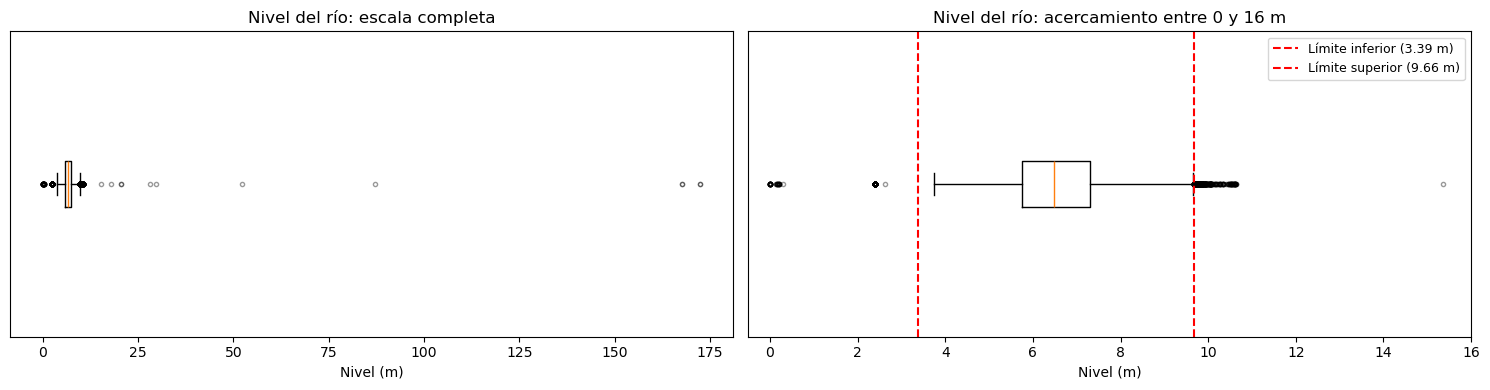

In [13]:
# Se trabaja sobre el DataFrame ya SIN duplicados y ordenado en el tiempo
df = df.sort_values("FechaObservacion").reset_index(drop=True)

# Se recalculan los límites del IQR sobre los datos sin duplicados
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df["fuera_iqr"] = (df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)

print(f"Q1 = {Q1:.2f} m | Q3 = {Q3:.2f} m | IQR = {IQR:.2f} m")
print(f"Límites del IQR: [{limite_inferior:.2f} m , {limite_superior:.2f} m]")
print(f"Registros fuera de los límites: {df['fuera_iqr'].sum()}")
print(f"   por debajo del límite inferior: {(df['ValorObservado'] < limite_inferior).sum()}")
print(f"   por encima del límite superior: {(df['ValorObservado'] > limite_superior).sum()}")

# Valores únicos más altos y más bajos: sirven para ver dónde terminan los valores posibles
valores_unicos = np.sort(df["ValorObservado"].unique())
print("\n15 valores únicos más bajos:", valores_unicos[:15])
print("15 valores únicos más altos:", valores_unicos[-15:])

# Diagrama de caja
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].boxplot(df["ValorObservado"], vert=False, whis=1.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.4))
axes[0].set_title("Nivel del río: escala completa")
axes[0].set_xlabel("Nivel (m)")
axes[0].set_yticks([])

axes[1].boxplot(df["ValorObservado"], vert=False, whis=1.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.4))
axes[1].axvline(limite_inferior, color="red", linestyle="--", label=f"Límite inferior ({limite_inferior:.2f} m)")
axes[1].axvline(limite_superior, color="red", linestyle="--", label=f"Límite superior ({limite_superior:.2f} m)")
axes[1].set_xlim(-0.5, 16)
axes[1].set_title("Nivel del río: acercamiento entre 0 y 16 m")
axes[1].set_xlabel("Nivel (m)")
axes[1].set_yticks([])
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

En la lista de valores más altos se ve que los niveles aumentan de forma continua hasta 10.64 m y luego saltan a 15.36 m, sin valores intermedios. Ese salto de casi 5 m marca dónde terminan los valores posibles, por lo que se toma 15 m como límite físico máximo.

En la lista de valores más bajos ocurre algo parecido: hay valores entre 0 y 0.3 m y luego el siguiente es 2.4 m. Un nivel de pocos centímetros no es posible en este punto del río, por lo que se toma 1 m como límite físico mínimo.

El diagrama de caja muestra visualmente el resultado del IQR. La caja representa el 50 % central de los datos (entre Q1 = 5.74 m y Q3 = 7.31 m), la línea dentro de ella es la mediana, los bigotes se extienden hasta el último valor que todavía está dentro de los límites del IQR (marcados con líneas rojas), y los puntos fuera de ellos son los registros considerados atípicos. El bigote inferior no llega hasta la línea del límite inferior (3.39 m) porque no hay ningún registro entre ese límite y 3.74 m; el bigote termina en el valor real más bajo dentro del rango. En la escala completa, la caja queda comprimida contra el extremo izquierdo porque algunos valores llegan a más de 170 m, lo que ya evidencia la presencia de errores. En el acercamiento se observa que hay atípicos en ambos lados de la caja: por debajo, con valores cercanos a 0 m y alrededor de 2.4 m, y por encima, entre unos 9.7 m y 10.6 m. El diagrama no permite saber cuáles de estos puntos son errores y cuáles son niveles reales del río, y por eso se analizan más adelante.

## **1.4.1. Clasificación de los valores atípicos**

El método IQR solo indica qué tan lejos está un dato del centro de la distribución, pero no indica si ese dato es un error. En una serie de nivel de río esto importa, porque los valores más altos pueden ser crecientes reales del río y los más bajos pueden ser temporadas secas. Si se eliminan, el modelo nunca vería esos eventos, y son justamente los más importantes de predecir. Además, el IQR no puede detectar errores cuyo valor parece normal, como un sensor que repite el mismo dato durante días.

Por esta razón, en vez de eliminar todo lo que el IQR marca, cada registro se clasifica con reglas basadas en el comportamiento físico del río:

| Categoría | Regla | Tratamiento |
|---|---|---|
| Error: valor imposible | Nivel < 1 m o > 15 m | Se elimina |
| Error: sensor pegado | El mismo valor exacto se repite 24 horas o más | Se elimina |
| Error: salto brusco | El valor se aleja más de 0.3 m de la mediana de las 24 horas a su alrededor, ya sea un punto suelto o un bloque de varias horas | Se elimina |
| Extremo real | Está fuera de los límites del IQR pero no cumple ninguna de las reglas anteriores | Se conserva |


### **Regla 1: valores físicamente imposibles**
Un nivel por debajo de 1 m significa que el sensor no registró bien la medición, ya que el río no baja a ese nivel en este punto. Los valores por encima del límite físico máximo corresponden a errores de transmisión.

In [ ]:
LIMITE_FISICO_MIN = 1.0   
LIMITE_FISICO_MAX = 15.0  

df["imposible"] = (df["ValorObservado"] < LIMITE_FISICO_MIN) | (df["ValorObservado"] > LIMITE_FISICO_MAX)

print(f"Registros con valores imposibles: {df['imposible'].sum()}")
imposibles = df.loc[df["imposible"], ["FechaObservacion", "ValorObservado"]]
display(imposibles)

Registros con valores imposibles: 48


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
19945,2007-04-22 17:00:00,20.49
19946,2007-04-22 19:00:00,167.67
22056,2007-07-22 03:00:00,172.42
45446,2010-03-25 11:00:00,0.00
61081,2012-01-08 08:00:00,15.36
62265,2012-02-27 05:00:00,87.22
62266,2012-02-27 06:00:00,28.16


Se encontraron 48 registros imposibles, que se pueden agrupar en tres casos:

- **Valores demasiado altos (12 registros):** entre 15.36 m y 172.42 m. Los valores de 2005 (20.49 m y 167.67 m el 22 de abril, y 172.42 m el 22 de julio) se repiten exactamente iguales, en el mismo día y hora, en 2007, lo que indica un error en el registro de los datos y no un comportamiento del río.
- **Valores cercanos a cero (17 registros):** entre el 18 y el 19 de septiembre de 2018 el sensor marcó entre 0.14 m y 0.30 m durante unas 17 horas seguidas, lo que corresponde a una falla continua del sensor.
- **Valores en 0 m (19 registros):** la mayoría ocurre en 2024 y 2025, siempre entre las 03:40 y las 04:00 de la madrugada. Que se repitan a la misma hora sugiere un reinicio o mantenimiento del equipo y no un evento real.

### **Regla 2: sensor pegado**
El sensor mide con precisión de centímetro, así que el nivel de un río real cambia aunque sea un poco a lo largo de un día. Cuando el mismo valor exacto se repite durante muchas horas seguidas, lo más probable es que el sensor dejó de medir y siguió enviando el último dato.

Para encontrar estos casos se divide la serie en tramos donde el valor no cambia. Un tramo nuevo empieza cuando el valor cambia o cuando hay más de 3 horas sin datos. Se usan 3 horas porque el sensor mide como máximo cada hora, así que 3 horas sin datos significa que se perdieron al menos dos mediciones seguidas. Si el valor es igual antes y después de un hueco así, no hay forma de saber qué pasó en medio, y unir esos datos haría parecer que el sensor estuvo pegado cuando en realidad no hubo datos.

In [9]:
HORAS_PEGADO = 24

# Empieza un "tramo" nuevo cada vez que el valor cambia o cuando hay más de
# 3 horas sin datos (así un hueco largo no une dos tramos distintos)
cambia_valor = df["ValorObservado"].ne(df["ValorObservado"].shift())
salto_tiempo = df["FechaObservacion"].diff() > pd.Timedelta(hours=3)
df["id_tramo"] = (cambia_valor | salto_tiempo).cumsum()

# Duración de cada tramo con valor constante
tramos = df.groupby("id_tramo").agg(
    valor=("ValorObservado", "first"),
    inicio=("FechaObservacion", "min"),
    fin=("FechaObservacion", "max"),
    registros=("ValorObservado", "size"),
)
tramos["duracion_h"] = (tramos["fin"] - tramos["inicio"]).dt.total_seconds() / 3600

print("Tramos en los que el valor no cambió durante:")
for h in [3, 6, 12, 24, 48]:
    print(f"   {h:>2} horas o más: {(tramos['duracion_h'] >= h).sum()} tramos")

tramos_pegados = tramos[tramos["duracion_h"] >= HORAS_PEGADO]
df["pegado"] = df["id_tramo"].isin(tramos_pegados.index)

print(f"\nTramos con sensor pegado (>= {HORAS_PEGADO} h): {len(tramos_pegados)}")
print(f"Registros afectados: {df['pegado'].sum()}")
display(tramos_pegados.sort_values("duracion_h", ascending=False))

# Valores de falla conocidos: si un valor ya se identificó como sensor pegado
# en un tramo largo y además está fuera de los límites del IQR, cualquier otra
# aparición de ese valor fuera de los límites corresponde a la misma falla
valores_falla = tramos_pegados.loc[
    (tramos_pegados["valor"] < limite_inferior) | (tramos_pegados["valor"] > limite_superior), "valor"
].unique()
marcar = df["ValorObservado"].isin(valores_falla) & df["fuera_iqr"] & ~df["pegado"]
df["pegado"] = df["pegado"] | marcar

print(f"\nValores de falla conocidos fuera del IQR: {valores_falla}")
print(f"Registros adicionales marcados por repetir un valor de falla: {marcar.sum()}")
print(f"Total de registros con sensor pegado: {df['pegado'].sum()}")

Tramos en los que el valor no cambió durante:
    3 horas o más: 4728 tramos
    6 horas o más: 955 tramos
   12 horas o más: 180 tramos
   24 horas o más: 56 tramos
   48 horas o más: 35 tramos

Tramos con sensor pegado (>= 24 h): 56
Registros afectados: 14034


,valor,inicio,fin,registros,duracion_h
id_tramo,,,,,
51392,6.39,2018-12-20 10:00:00,2019-04-02 01:00:00,2464,2463.0
52454,6.39,2019-07-08 18:00:00,2019-09-14 23:00:00,1637,1637.0
42874,4.28,2015-12-26 20:00:00,2016-02-29 08:00:00,1549,1548.0
50373,6.55,2018-07-22 00:00:00,2018-09-17 21:00:00,1390,1389.0
49199,4.27,2018-01-27 23:00:00,2018-03-11 12:00:00,1016,1021.0
53608,5.15,2020-02-25 01:00:00,2020-03-16 21:00:00,501,500.0
53605,5.15,2020-01-25 18:00:00,2020-02-11 20:00:00,411,410.0
49200,4.27,2018-03-11 16:00:00,2018-03-28 13:00:00,403,405.0
52455,6.39,2019-09-18 00:00:00,2019-09-30 11:00:00,300,299.0



Valores de falla conocidos fuera del IQR: [2.4]
Registros adicionales marcados por repetir un valor de falla: 35
Total de registros con sensor pegado: 14069


La tabla muestra que es normal que el valor se repita algunas horas (955 tramos de 6 h o más), ya que el nivel del río puede mantenerse estable por periodos cortos. Sin embargo, que el mismo valor exacto se mantenga 24 horas o más es poco común (56 tramos), por lo que se toma 24 horas como umbral. Un día completo es el periodo en el que el nivel del río debería cambiar al menos un centímetro, incluso en temporada seca. Se consideró usar 48 horas, pero solo cambiaría la clasificación de 21 tramos cortos (56 − 35), mientras que la mayoría de los registros afectados pertenecen a tramos de semanas o meses que quedan marcados con cualquiera de los dos umbrales.

Se encontraron 56 tramos con el sensor pegado, que suman 14034 registros. Algunos duran semanas o meses: el más largo va del 20 de diciembre de 2018 al 2 de abril de 2019, con un valor fijo de 6.39 m durante 2463 horas (unos 103 días). También hay tramos largos de 6.39 m entre julio y septiembre de 2019, de 4.28 m entre diciembre de 2015 y febrero de 2016, y de 6.55 m entre julio y septiembre de 2018. Ningún río mantiene el mismo nivel, al centímetro, durante meses.

La mayoría de estos valores (6.39 m, 6.55 m, 5.15 m, 4.28 m) están dentro de los límites del IQR, por lo que ese método no podía detectarlos: el valor parece normal y lo que lo delata es que no cambia en el tiempo. Además, el tramo de 6.39 m de 2019 coincide con el periodo en que aparecieron los registros duplicados, lo que sugiere una falla general del equipo en esas fechas.

Al revisar los resultados de la clasificación se encontraron registros con un valor de 2.40 m en los que el sensor quedó fijo durante 151 horas en febrero de 2009, y está por debajo del límite inferior del IQR. Por eso se agregó una condición: si un valor ya se identificó como sensor pegado en un tramo largo y además está fuera de los límites del IQR, cualquier otra aparición de ese valor fuera de esos límites se considera la misma falla. La condición de estar fuera del IQR evita marcar valores como 6.39 m o 4.28 m, que también aparecieron pegados pero que el río sí puede alcanzar en condiciones normales.

El único valor que cumplió esta condición fue 2.40 m, con 35 registros adicionales. Con ellos, el total de registros con sensor pegado es de 14069.

### **Regla 3: saltos bruscos**
Se espera que el nivel de un río tan grande como el Magdalena cambie de forma gradual, del orden de centímetros por hora. Por eso, si en algún registro el nivel subiera o bajara de golpe un metro o más y poco después volviera a su valor anterior, sería un comportamiento poco probable para el río y podría clasificarse como un error del sensor. Para comprobar esta suposición se calculó cuánto cambia el nivel entre dos mediciones separadas exactamente una hora, excluyendo los errores ya identificados en las reglas 1 y 2.

In [10]:
validos = df[~(df["imposible"] | df["pegado"])].copy()
validos["horas"] = validos["FechaObservacion"].diff().dt.total_seconds() / 3600
validos["cambio"] = validos["ValorObservado"].diff().abs()

# Solo pares de mediciones separadas exactamente 1 hora
cambio_horario = validos.loc[validos["horas"] == 1, "cambio"]
print("Cambio del nivel entre dos mediciones separadas 1 hora (m):")
print(cambio_horario.quantile([0.50, 0.90, 0.99, 0.999]).round(3).to_string())
print(f"\nCambios de más de 1 m en una hora: {(cambio_horario > 1).sum()} de {len(cambio_horario)}")

Cambio del nivel entre dos mediciones separadas 1 hora (m):
0.500    0.01
0.900    0.02
0.990    0.08
0.999    2.70

Cambios de más de 1 m en una hora: 367 de 100474


Se puede evidenciar que en la mitad de los casos el nivel cambió 1 cm o menos, en el 90 % menos de 2 cm y en el 99 % menos de 8 cm, lo que confirma que el río cambia de forma gradual. Sin embargo, el 0.1 % restante presenta cambios de hasta 2.70 m en una sola hora, y se encontraron 367 cambios de más de 1 m (0.37 % de los casos). El paso de 8 cm a varios metros entre los percentiles 99 y 99.9 muestra que estos cambios no son una variación mayor de lo normal, sino un comportamiento distinto, propio de errores del sensor, que se busca detectar con la siguiente regla.
Para detectarlos se calcula, para cada registro, la mediana de los valores de las 12 horas anteriores y las 12 horas posteriores (mediana móvil centrada de 24 horas). Las decisiones de este método son:

- **Mediana y no media:** la media se deja arrastrar por los mismos valores erróneos que se quieren detectar; la mediana no, mientras los datos correctos sean la mayoría de la ventana.
- **Ventana de 24 horas:** los bloques de saltos observados duran algunas horas, así que en una ventana de 24 horas los datos correctos siguen siendo mayoría y la mediana representa el nivel real. Una ventana más corta podría quedar dominada por un bloque de error. Una más larga dejaría de seguir los cambios reales del río, porque en varios días el nivel sí puede subir o bajar.
- **Ventana centrada:** se miran las horas antes y después del registro, porque un error se reconoce justamente porque el valor no encaja con lo que pasó antes ni con lo que pasó después.
- **Mínimo de 3 datos en la ventana:** con menos datos la mediana no es confiable, así que esos registros no se evalúan.
- **Sin los errores ya detectados:** los valores imposibles y los del sensor pegado se excluyen del cálculo de la mediana, porque si no, la referencia quedaría contaminada.

Percentiles de la desviación respecto a la mediana móvil de 24 h (m):
0.500    0.005
0.900    0.020
0.990    0.370
0.999    1.610

Registros que superarían cada umbral candidato:
   > 0.1 m: 3368
   > 0.2 m: 3012
   > 0.3 m: 2923
   > 0.5 m: 2707
   > 1.0 m: 1246


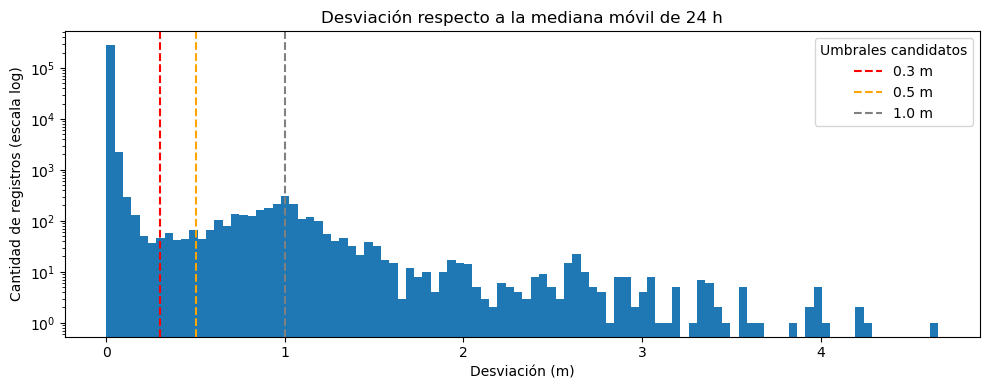


Registros por encima del límite superior del IQR, por mes:


,registros,desviacion_min,desviacion_max
FechaObservacion,,,
2020-12,35,0.000,0.075
2022-09,66,1.110,2.060
2022-10,336,0.710,1.710
2022-11,39,0.310,1.370
2022-12,6,0.570,1.450
2024-12,1,2.475,2.475
2025-05,1,1.850,1.850


In [11]:
VENTANA = "24h"

serie = df.set_index("FechaObservacion")["ValorObservado"]

# La mediana de referencia se calcula sin los errores ya identificados
ya_es_error = (df["imposible"] | df["pegado"]).to_numpy()
serie_referencia = serie.where(~ya_es_error)

# Mediana móvil centrada: para cada registro, la mediana de las 12 h antes y 12 h después
mediana_movil = serie_referencia.rolling(VENTANA, center=True, min_periods=3).median()
df["desviacion"] = (serie - mediana_movil).abs().to_numpy()
desv_validas = df.loc[~ya_es_error, "desviacion"].dropna()

print("Percentiles de la desviación respecto a la mediana móvil de 24 h (m):")
print(desv_validas.quantile([0.50, 0.90, 0.99, 0.999]).round(3).to_string())

print("\nRegistros que superarían cada umbral candidato:")
for u in [0.1, 0.2, 0.3, 0.5, 1.0]:
    print(f"   > {u} m: {(desv_validas > u).sum()}")

# Evidencia 1: histograma de la desviación con los umbrales candidatos
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(desv_validas, bins=100, color="#1f77b4")
ax.set_yscale("log")
for u, c in [(0.3, "red"), (0.5, "orange"), (1.0, "gray")]:
    ax.axvline(u, color=c, linestyle="--", label=f"{u} m")
ax.set_title("Desviación respecto a la mediana móvil de 24 h")
ax.set_xlabel("Desviación (m)")
ax.set_ylabel("Cantidad de registros (escala log)")
ax.legend(title="Umbrales candidatos")
plt.tight_layout()
plt.show()

# Evidencia 2: registros por encima del límite superior del IQR (que no son errores ya
# detectados), agrupados por mes, con su desviación mínima y máxima
altos = df[(df["ValorObservado"] > limite_superior) & ~ya_es_error]
resumen_altos = altos.groupby(altos["FechaObservacion"].dt.to_period("M"))["desviacion"].agg(
    registros="size", desviacion_min="min", desviacion_max="max"
).round(3)
print("\nRegistros por encima del límite superior del IQR, por mes:")
display(resumen_altos)

El histograma muestra dos grupos: la gran mayoría de los registros se aleja apenas unos centímetros de su mediana (el comportamiento normal del río), y un segundo grupo, mucho más pequeño, se concentra alrededor de 1 m de desviación (los saltos del sensor). Entre ambos hay un valle con muy pocos registros.

La tabla de registros por encima del límite superior del IQR permite comparar los dos casos directamente. En diciembre de 2020 los 35 registros se alejan como máximo 0.075 m de su mediana: el nivel subió y se mantuvo junto con la tendencia de su propio día, como en una creciente real. En cambio, en todos los demás meses (septiembre a diciembre de 2022, diciembre de 2024 y mayo de 2025) los valores se alejan como mínimo 0.31 m, y la mayoría más de 0.5 m: suben por encima de la tendencia de su día y luego vuelven a ella, como los saltos del sensor. Entre 0.075 m y 0.31 m no hay ningún registro, por lo que cualquier umbral dentro de ese rango separa ambos grupos.

El umbral se ajustó en varias pruebas. Con 1 m se dejaban pasar saltos de 0.8 a 0.95 m con la misma forma que los demás errores (por ejemplo, en septiembre de 2022), y con 0.5 m se dejaban pasar puntas de salto como las de noviembre de 2022. Por eso se tomó 0.3 m: queda dentro del rango vacío entre la creciente real (0.075 m) y el salto más pequeño encontrado (0.31 m), y coincide con la zona del valle del histograma.

In [12]:
UMBRAL_PICO = 0.3  # metros

df["pico"] = (df["desviacion"] > UMBRAL_PICO) & ~df["imposible"] & ~df["pegado"]

# ¿Los saltos vienen sueltos o en bloques?
rachas = (df["pico"] != df["pico"].shift()).cumsum()[df["pico"]].value_counts()
print(f"Registros clasificados como salto brusco (> {UMBRAL_PICO} m): {df['pico'].sum()}")
print(f"   saltos de un solo registro: {(rachas == 1).sum()}")
print(f"   bloques de 2 o más registros: {(rachas > 1).sum()}")
print("\nSaltos bruscos por año:")
print(df.loc[df["pico"], "FechaObservacion"].dt.year.value_counts().sort_index().to_string())

Registros clasificados como salto brusco (> 0.3 m): 2923
   saltos de un solo registro: 422
   bloques de 2 o más registros: 402

Saltos bruscos por año:
FechaObservacion
2005      90
2007      95
2008     346
2009       6
2010       2
2011       4
2012       1
2017      21
2018      17
2019      12
2020      49
2021       1
2022    1050
2023     174
2024     166
2025     879
2026      10


Se encontraron 2923 registros con saltos bruscos, agrupados en 422 saltos de un solo registro y 402 bloques de dos o más registros seguidos. Aunque la cantidad de saltos sueltos y de bloques es parecida, los bloques reúnen 2501 de los 2923 registros (cerca del 86 %). Esto muestra que el error más común del sensor no es un punto aislado, sino un desplazamiento temporal del nivel que dura varias horas. Los años con más casos son 2008, 2022 y 2025.

### **Clasificación final y comparación con el IQR**
Si un registro cumple varias reglas a la vez, se le asigna una sola categoría con este orden de prioridad: valor imposible, sensor pegado, salto brusco y, por último, extremo real. Los errores van antes que el extremo real porque un valor fuera del IQR que además cumple una regla de error no debe conservarse. Entre los errores, primero va el más evidente, para que el conteo de cada categoría refleje la causa principal.

In [15]:
# Clasificación final de cada registro (si cumple varias reglas, gana la de más abajo)
df["tipo_atipico"] = "normal"
df.loc[df["fuera_iqr"], "tipo_atipico"] = "extremo_real"
df.loc[df["pico"], "tipo_atipico"] = "error_salto_brusco"
df.loc[df["pegado"], "tipo_atipico"] = "error_sensor_pegado"
df.loc[df["imposible"], "tipo_atipico"] = "error_imposible"

# Comparación: qué hubiera hecho el IQR solo frente a la clasificación por reglas
tabla_comparacion = pd.crosstab(
    df["tipo_atipico"],
    df["fuera_iqr"].map({True: "Fuera del IQR", False: "Dentro del IQR"}),
    margins=True, margins_name="Total",
    rownames=["Clasificación"], colnames=["Según IQR"],
)
display(tabla_comparacion)

es_error = df["tipo_atipico"].str.startswith("error")
print(f"Atípicos según IQR: {df['fuera_iqr'].sum()}")
print(f"   de ellos son extremos reales (se conservan): {(df['tipo_atipico'] == 'extremo_real').sum()}")
print(f"   de ellos son errores: {(df['fuera_iqr'] & es_error).sum()}")
print(f"Errores que el IQR NO detectaba: {(~df['fuera_iqr'] & es_error).sum()}")

# ¿Cuándo ocurren los extremos reales? Si son reales, deberían concentrarse
# en ciertos años y temporadas, no repartirse al azar
extremos = df[df["tipo_atipico"] == "extremo_real"]
nivel = np.where(extremos["ValorObservado"] > limite_superior, "Nivel alto", "Nivel bajo")

print("\nExtremos reales por año:")
display(pd.crosstab(extremos["FechaObservacion"].dt.year, nivel, rownames=["Año"], colnames=["Tipo"]))
print("Extremos reales por mes:")
display(pd.crosstab(extremos["FechaObservacion"].dt.month, nivel, rownames=["Mes"], colnames=["Tipo"]))

Según IQR,Dentro del IQR,Fuera del IQR,Total
Clasificación,,,
error_imposible,0,48,48
error_salto_brusco,2473,450,2923
error_sensor_pegado,13882,187,14069
extremo_real,0,35,35
normal,280747,0,280747
Total,297102,720,297822


Atípicos según IQR: 720
   de ellos son extremos reales (se conservan): 35
   de ellos son errores: 685
Errores que el IQR NO detectaba: 16355

Extremos reales por año:


Tipo,Nivel alto
Año,
2020,35


Extremos reales por mes:


Tipo,Nivel alto
Mes,
12,35


La tabla compara qué hubiera pasado si se usara solo el IQR:
- De los 720 registros que el IQR marcaba como atípicos, solo 35 son extremos reales que se conservan; los otros 685 son errores.
- Además, el IQR no detectaba 16355 errores que tienen valores dentro del rango normal, principalmente tramos con el sensor pegado (13882) y saltos bruscos (2473).

Es decir, si se hubiera usado solo el IQR, se habrían eliminado 35 valores reales del río y se habrían conservado más de 16 mil valores erróneos. Esto justifica haber clasificado los atípicos con reglas físicas en lugar de eliminar directamente lo que el IQR marca.

Los 35 extremos reales son todos niveles altos y pertenecen a un solo evento: la creciente de diciembre de 2020, cuando el río se mantuvo alrededor de 9.7 m durante varios días. Este evento ocurre al final de la segunda temporada de lluvias del año en Colombia, y en noviembre de 2020 el IDEAM declaró alerta roja en varios sectores del río Magdalena, incluido el tramo entre El Banco y Plato, por el aumento del nivel asociado al fenómeno de La Niña (El Heraldo, 2020). Además, durante este evento cada valor se aleja como máximo 0.075 m de la mediana de su día, es decir, el nivel subió y se mantuvo de forma gradual, que es el comportamiento de una creciente real y no el de una falla del sensor. Por eso estos valores se conservan aunque superen el límite del IQR.

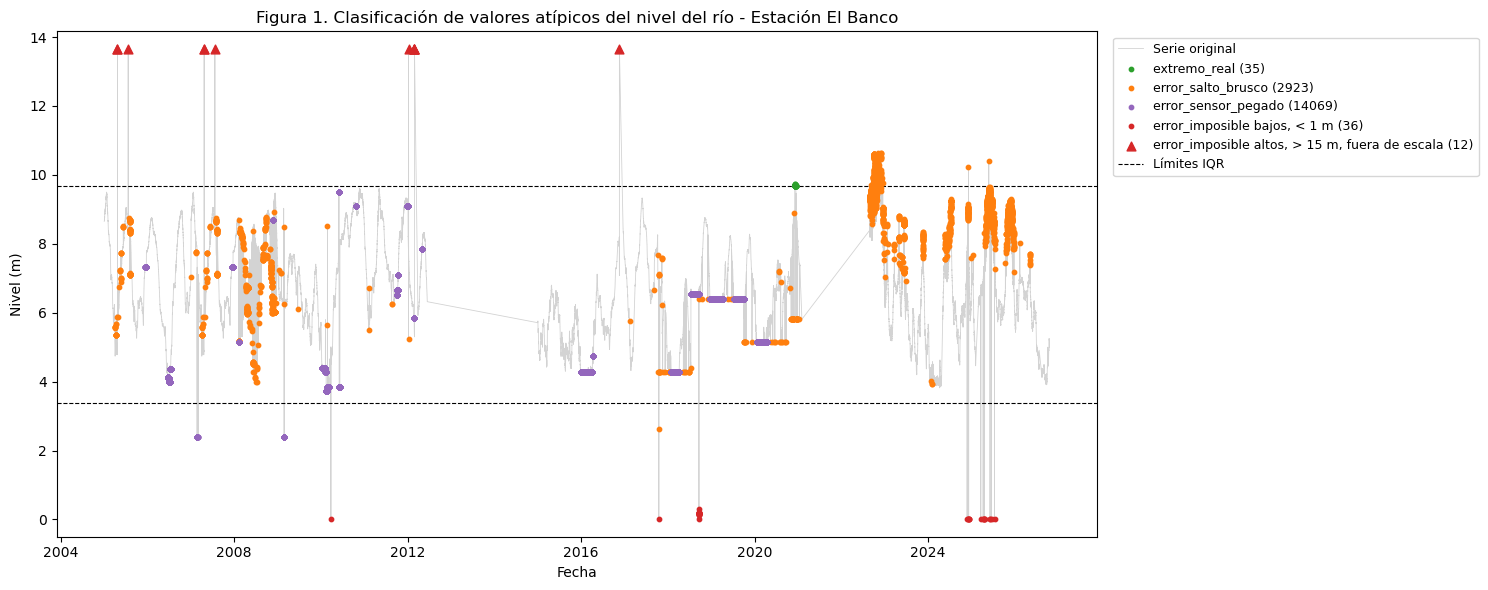

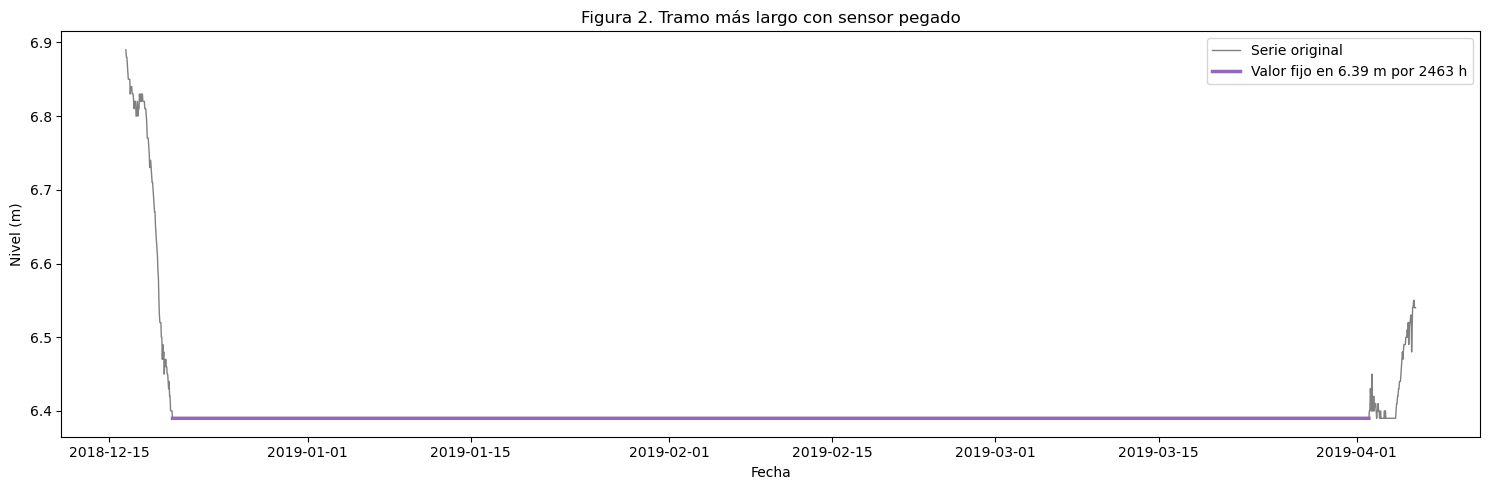

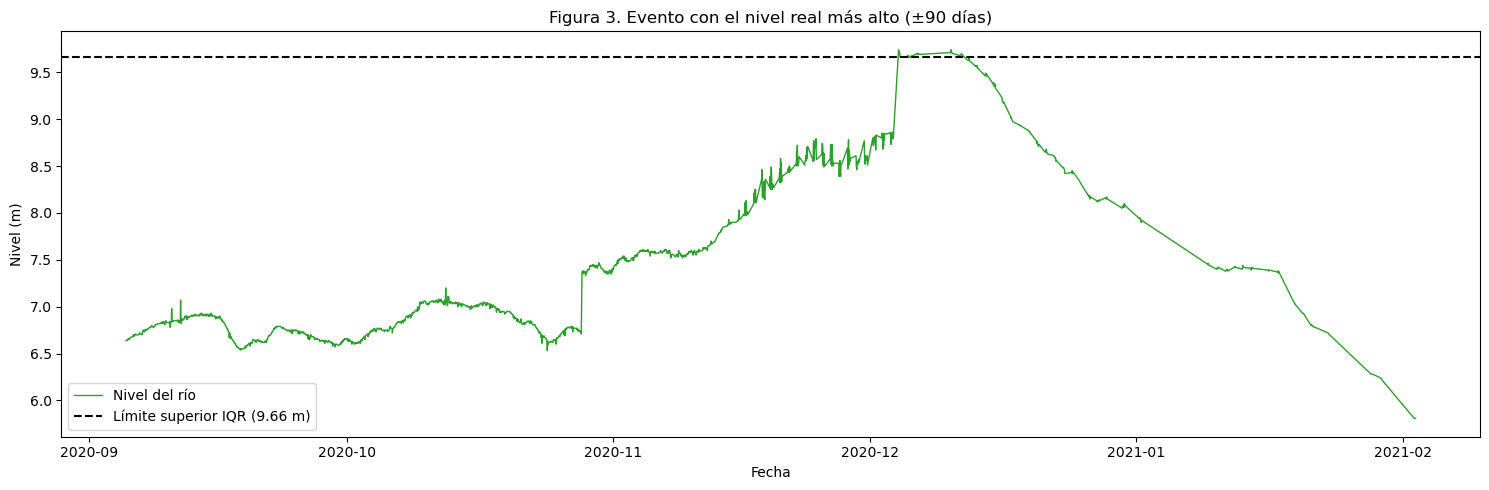

In [19]:
colores = {
    "extremo_real": "#2ca02c",
    "error_salto_brusco": "#ff7f0e",
    "error_sensor_pegado": "#9467bd",
    "error_imposible": "#d62728",
}
tope_y = limite_superior + 4  

# Figura 1: serie completa con cada tipo de atípico marcado
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df["FechaObservacion"], df["ValorObservado"].clip(upper=tope_y),
        color="lightgray", linewidth=0.6, label="Serie original")
for tipo, color in colores.items():
    sub = df[df["tipo_atipico"] == tipo]
    if tipo == "error_imposible":
        # Los imposibles altos (> 15 m) no caben en la escala: se dibujan como triángulos en el borde superior
        altos = sub[sub["ValorObservado"] > tope_y]
        bajos = sub[sub["ValorObservado"] <= tope_y]
        ax.scatter(bajos["FechaObservacion"], bajos["ValorObservado"], s=10, color=color,
                   label=f"{tipo} bajos, < 1 m ({len(bajos)})", zorder=3)
        ax.scatter(altos["FechaObservacion"], [tope_y] * len(altos), s=40, marker="^", color=color,
                   label=f"{tipo} altos, > 15 m, fuera de escala ({len(altos)})", zorder=3)
    else:
        ax.scatter(sub["FechaObservacion"], sub["ValorObservado"], s=10, color=color,
                   label=f"{tipo} ({len(sub)})", zorder=3)
ax.axhline(limite_superior, color="black", linestyle="--", linewidth=0.8, label="Límites IQR")
ax.axhline(limite_inferior, color="black", linestyle="--", linewidth=0.8)
ax.set_ylim(-0.5, tope_y + 0.5)
ax.set_title("Figura 1. Clasificación de valores atípicos del nivel del río - Estación El Banco")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Figura 2: acercamiento al tramo más largo con sensor pegado
t = tramos_pegados.sort_values("duracion_h").iloc[-1]
ventana = df[(df["FechaObservacion"] >= t["inicio"] - pd.Timedelta(days=4)) &
             (df["FechaObservacion"] <= t["fin"] + pd.Timedelta(days=4))]
pegados = ventana[ventana["pegado"]]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="gray", linewidth=1, label="Serie original")
ax.plot(pegados["FechaObservacion"], pegados["ValorObservado"], color="#9467bd", linewidth=2.5,
        label=f"Valor fijo en {t['valor']} m por {t['duracion_h']:.0f} h")
ax.set_title("Figura 2. Tramo más largo con sensor pegado")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend()
plt.tight_layout()
plt.show()

# Figura 3: evento con el extremo real más alto (±90 días), sin los errores
fecha_max = extremos.loc[extremos["ValorObservado"].idxmax(), "FechaObservacion"]
ventana = df[(df["FechaObservacion"] >= fecha_max - pd.Timedelta(days=90)) &
             (df["FechaObservacion"] <= fecha_max + pd.Timedelta(days=90)) &
             ~df["tipo_atipico"].str.startswith("error")]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="#2ca02c", linewidth=1, label="Nivel del río")
ax.axhline(limite_superior, color="black", linestyle="--", label=f"Límite superior IQR ({limite_superior:.2f} m)")
ax.set_title("Figura 3. Evento con el nivel real más alto (±90 días)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend()
plt.tight_layout()
plt.show()

**Figura 1.** Los errores aparecen a lo largo de todo el periodo, pero cada tipo tiene un patrón distinto. Los tramos con sensor pegado se ven como líneas horizontales, sobre todo entre 2015 y 2020 (por ejemplo, en 4.27 m, 5.15 m, 6.39 m y 6.55 m), con valores que están dentro de los límites del IQR. Los saltos bruscos se concentran entre 2007 y 2009 y desde finales de 2022, cuando el sensor empezó a medir con más frecuencia. Los valores imposibles altos (mayores a 15 m, hasta 172.42 m) no caben en la escala de la gráfica: la serie sube hasta el borde superior y el punto se marca con un triángulo para indicar que el valor real está fuera del rango mostrado. Los imposibles bajos aparecen cerca de 0 m, sobre todo en 2018, 2024 y 2025. También se ven periodos largos sin datos, marcados por líneas rectas: entre mediados de 2012 y 2015, y entre 2021 y agosto de 2022.

**Figura 2.** El tramo pegado más largo muestra el nivel bajando de forma natural hasta 6.39 m a mediados de diciembre de 2018 y luego una línea completamente plana durante 2463 horas, hasta inicios de abril de 2019, cuando el valor vuelve a cambiar. Esto es muy distinto del comportamiento normal de la serie, en la que el mismo valor rara vez se repite más de 24 horas

**Figura 3.** El evento con el nivel real más alto corresponde a la creciente de finales de 2020. El río sube desde unos 6.5 m en septiembre hasta cerca de 9.7 m a inicios de diciembre, se mantiene en ese nivel durante varios días y luego desciende de forma continua durante dos meses, hasta unos 5.8 m en febrero de 2021. En la subida se ven dos tramos más bruscos (a finales de octubre y de noviembre), que pueden deberse a subidas rápidas por las lluvias o a periodos sin datos que la gráfica une con una línea recta. Aun así, el comportamiento general (un ascenso de semanas, varios días en la cima y un descenso lento y sostenido) es el de una creciente real, a diferencia de los errores del sensor, que suben y bajan en cuestión de horas. Por eso estos valores se conservan aunque superen el límite del IQR.

### **Tratamiento de los errores**
Los registros clasificados como error se convierten en valores nulos en lugar de eliminar las filas. Así se conserva la línea de tiempo completa y queda marcado que en esa fecha no hay un dato confiable. Si se eliminaran las filas, las fechas que quedan aparecerían como consecutivas aunque entre ellas falten horas o días, lo cual afectaría la construcción de variables basadas en el pasado. Los extremos reales no se modifican.

Los huecos que dejan los errores se pueden rellenar con interpolación lineal, es decir, trazando una línea recta entre el último dato válido antes del hueco y el primero después. Esto solo tiene sentido en huecos cortos, donde el río no alcanza a cambiar mucho; en huecos largos, una línea recta inventaría un comportamiento que no se observó. Para decidir hasta qué tamaño de hueco se puede interpolar, se midió el error que comete la interpolación sobre datos reales: se toman mediciones que sí existen, se estiman con una línea recta entre el dato de antes y el de después como si no estuvieran, y se compara la estimación con el valor real.

In [20]:
# Error que comete la interpolación lineal según el tamaño del hueco
validos = df[~df["tipo_atipico"].str.startswith("error")].set_index("FechaObservacion")["ValorObservado"]
validos = validos[~validos.index.duplicated()]
horario = validos[validos.index.minute == 0]  

print("Error al estimar un valor con una línea recta entre el dato anterior y el siguiente:")
for h in [2, 4, 6, 8, 12, 24]:
    mitad = pd.Timedelta(hours=h / 2)
    antes = horario.reindex(horario.index - mitad).to_numpy()
    despues = horario.reindex(horario.index + mitad).to_numpy()
    estimado = (antes + despues) / 2  # punto medio de la línea recta
    error = np.abs(horario.to_numpy() - estimado)
    error = error[~np.isnan(error)]
    print(f"   hueco de {h:>2} h: mediana {np.median(error):.3f} m | percentil 95 {np.percentile(error, 95):.3f} m"
          f" | casos evaluados {len(error)}")

Error al estimar un valor con una línea recta entre el dato anterior y el siguiente:
   hueco de  2 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 127761
   hueco de  4 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 126824
   hueco de  6 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 126016
   hueco de  8 h: mediana 0.005 m | percentil 95 0.030 m | casos evaluados 125419
   hueco de 12 h: mediana 0.005 m | percentil 95 0.030 m | casos evaluados 124599
   hueco de 24 h: mediana 0.010 m | percentil 95 0.045 m | casos evaluados 123393


La mitad de las estimaciones se equivoca 0.5 cm o menos para huecos de hasta 12 horas. El percentil 95 se mantiene en 2.5 cm para huecos de 2, 4 y 6 horas, y a partir de 8 horas empieza a crecer (3 cm con 8 y 12 horas, y 4.5 cm con 24 horas). Por eso se tomó 6 horas como límite: es el hueco más grande que se puede rellenar sin que el error aumente respecto al de un hueco de 2 horas. Ese error, de unos pocos centímetros, es del mismo orden que la variación normal del río en una hora. Los huecos de más de 6 horas se dejan vacíos.

Esta evaluación estima el punto ubicado justo en la mitad del hueco, que es donde la línea recta suele alejarse más del valor real, por lo que representa el caso menos favorable dentro de cada hueco.

El límite se mide en tiempo y no en número de filas porque el sensor no siempre mide con la misma frecuencia (a veces cada hora, a veces cada 10 minutos). Con un límite en filas, 6 registros serían 6 horas en unos periodos y solo 1 hora en otros. Por la misma razón se usa `method="time"`, que tiene en cuenta cuánto tiempo pasó entre los datos.

In [21]:
# Se guarda una copia con la clasificación por si se necesita más adelante
df_clasificado = df.copy()

# Los errores se convierten en nulos. Los extremos reales NO se tocan
es_error = df["tipo_atipico"].str.startswith("error")
df["ValorObservado"] = df["ValorObservado"].mask(es_error)
print(f"Errores convertidos en nulos: {es_error.sum()}")

# Interpolación solo en huecos cortos, medidos en TIEMPO y no en número de filas
MAX_HUECO = pd.Timedelta(hours=6)  

serie = df.set_index("FechaObservacion")["ValorObservado"]
es_nulo = serie.isna()
tiempos = serie.index.to_series()
anterior_valido = tiempos.where(~es_nulo).ffill()   
siguiente_valido = tiempos.where(~es_nulo).bfill()  
duracion_hueco = siguiente_valido - anterior_valido

rellenable = es_nulo & (duracion_hueco <= MAX_HUECO)
interpolada = serie.interpolate(method="time", limit_area="inside")
df["ValorObservado"] = serie.where(~rellenable, interpolada).to_numpy()

print(f"Nulos rellenados por interpolación (huecos de hasta {MAX_HUECO}): {rellenable.sum()}")
print(f"Nulos que quedan (huecos largos, se dejan vacíos): {df['ValorObservado'].isna().sum()}")

# Se dejan solo las dos columnas originales para los pasos siguientes
df = df[["FechaObservacion", "ValorObservado"]]
display(df["ValorObservado"].describe().to_frame().T)

Errores convertidos en nulos: 17040
Nulos rellenados por interpolación (huecos de hasta 0 days 06:00:00): 2568
Nulos que quedan (huecos largos, se dejan vacíos): 14472


,count,mean,std,min,25%,50%,75%,max
ValorObservado,283350.0,6.586679,1.2424,3.82,5.79,6.55,7.36,9.74


Se convirtieron en nulos 17040 errores (48 imposibles, 14069 de sensor pegado y 2923 saltos bruscos). De ellos, 2568 se rellenaron por interpolación y 14472 quedaron vacíos por pertenecer a huecos largos, principalmente los tramos de sensor pegado que duraron semanas o meses. Los vacíos no afectan la agregación diaria o semanal, porque el promedio con `.mean()` ignora los valores nulos, pero sí dejan semanas sin datos que se deben tener en cuenta al construir las variables de rezago.

Después del tratamiento, el nivel queda entre 3.82 m y 9.74 m, con una media de 6.59 m y una mediana de 6.55 m. El máximo de 9.74 m corresponde a la creciente real de diciembre de 2020, que se conservó. La desviación estándar bajó de 1.40 m a 1.24 m, porque ya no la inflan valores imposibles como 172.42 m. Además, la media y la mediana quedaron casi iguales, lo que indica que la distribución ya no está distorsionada por valores extremos erróneos.

**Limitación:** en algunos periodos, por ejemplo en agosto de 2005, el nivel cambia de golpe cerca de un metro y se queda en el nuevo valor, en lugar de volver al anterior. Esto sugiere un cambio en la referencia del sensor (reinstalación o recalibración) más que un cambio real del río. Como no es posible saber cuál de los dos niveles es el correcto, estos escalones no se corrigieron y se dejan como una limitación de los datos.

# **1.5. Agrupación por fecha**
Se evalúa cuántos registros aporta el sensor por día.

In [22]:
# Agrupamos por fecha (sin la hora) y contamos cuántas mediciones hubo cada día
observaciones_por_dia = (df["FechaObservacion"].dt.date.value_counts().sort_index())

print("--- Resumen estadístico de observaciones por día ---")
display(observaciones_por_dia.describe())

# Visualizamos los primeros días para ver si hay días con más registros de lo normal
print("\n--- Conteo de registros en los primeros días ---")
display(observaciones_por_dia.head(5))

--- Resumen estadístico de observaciones por día ---


count    6259.00000
mean       47.58300
std        47.39327
min         1.00000
25%        24.00000
50%        24.00000
75%        24.00000
max       146.00000
Name: count, dtype: float64


--- Conteo de registros en los primeros días ---


FechaObservacion
2005-01-01     7
2005-01-02    24
2005-01-03    24
2005-01-04    24
2005-01-05    24
Name: count, dtype: int64

El análisis confirma que el sensor mantiene una cobertura robusta y constante con una mediana de 24 registros diarios. A pesar de haber identificado días con con una menor cantidad de mediciones (con un mínimo de 13 registros diarios), el comportamiento general refleja una alta confiabilidad operativa en la ventana temporal estudiada.

In [23]:
# Filtramos saltos estrictamente mayores a 3 horas
umbral_gap = pd.Timedelta(hours=3)
periodos_sin_info = df[df["diferencia_tiempo"] > umbral_gap]

print(f"Se encontraron {len(periodos_sin_info)} periodos sin información:")
display(periodos_sin_info[["fechaobservacion", "diferencia_tiempo"]])

KeyError: 'diferencia_tiempo'

Al filtrar los intervalos de tiempo superiores a 3 horas, se identificaron únicamente 10 interrupciones en todo el periodo de estudio. La gran mayoría de estos eventos corresponden a retrasos operativos menores de entre 4 y 11 horas. El único vacío de información significativo se registró el 20 de agosto de 2026 con una duración de 2 días y 2 horas. Esto evidencia que, fuera de eventos técnicos aislados, la estación presenta una continuidad robusta y confiable para la serie temporal.

Se crea un dataframe temporal, donde la variable temporal se convierte en el índice del dataframe, permitiendo aplicar operaciones de remuestreo para calcular tanto el promedio diario como semanal del nivel del río.

In [ ]:
# Asegurarnos de que el DataFrame tiene la fecha como índice temporal
df_temp = df.copy()
df_temp["fechaobservacion"] = pd.to_datetime(df_temp["fechaobservacion"])
df_temp = df_temp.set_index("fechaobservacion")

# Ordenamos el índice temporal por seguridad
df_temp = df_temp.sort_index()

# Agregación diaria: promedio del nivel por día ('D')
df_diario = df_temp.resample("D")["valorobservado"].mean()

# Agregación semanal: promedio del nivel por semana ('W')
df_semanal = df_temp.resample("W")["valorobservado"].mean()

# Comparar cuántos puntos (filas) produce cada alternativa
print(f"Puntos generados por la agregación DIARIA: {len(df_diario)}")
print(f"Puntos generados por la agregación SEMANAL: {len(df_semanal)}")

# Primeras filas de cada uno para contrastar
print("\n--- Primeros registros Agregación Diaria ---")
display(df_diario.head())

print("\n--- Primeros registros Agregación Semanal ---")
display(df_semanal.head())

# **1.6. Visualización de la serie temporal**

In [ ]:

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Graficar la serie diaria de fondo (más delgada y traslúcida)
plt.plot(
    df_diario.index,
    df_diario.values,
    color="#aec7e8",
    linewidth=1.2,
    label="Promedio Diario (Detalle)",
)

# Graficar la serie semanal encima (más gruesa y destacada)
plt.plot(
    df_semanal.index,
    df_semanal.values,
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Promedio Semanal (Variable Objetivo)",
)

# Títulos y formato
plt.title(
    (
        "Comparativa de Agregación Temporal: Promedio Diario vs. Promedio Semanal"
        " - Estación El Banco"
    ),
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Fecha", fontsize=12, labelpad=10)
plt.ylabel("Nivel Observado (m)", fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.legend(loc="upper left", fontsize=11)
plt.tight_layout()

plt.show()

La gráfica permite contrastar la fluctuación detallada del promedio diario frente al comportamiento suavizado del promedio semanal.

**Análisis visual:**

La curva azul claro (promedio diario) evidencia la alta frecuencia de las mediciones y la presencia de los picos correspondientes a las ondas de avenida a finales de septiembre e inicios de octubre.

La línea azul oscura (promedio semanal) filtra eficazmente el ruido telemático de alta frecuencia y traza con claridad la tendencia macro del nivel del río. Esta suavización confirma que el modelado a escala semanal es la estrategia correcta para capturar la dinámica hidrológica sin las distorsiones de las variaciones intra-diarias